# Étape 5 — Intégration : le système complet

**Objectif :** réunir le détecteur (étape 3) et le classifieur (étape 4) dans une
seule application, qui prend une image satellite et rend la liste de ses avions :
leur boîte, leur type et une confiance.

    image  ->  1. détecteur YOLO11n  ->  une boîte par avion
           ->  une vignette autour de chaque boîte (make_crop, comme à l'étape 2)
           ->  2. classifieur ResNet-18  ->  le type, de A1 à A20

**Confiance finale = confiance du détecteur × confiance du classifieur.** Un avion
n'est retenu que si on est sûr à la fois que c'est un avion **et** de son type.

Tout tourne sur le processeur, environ 0,2 seconde par image.

Pré-requis : les modèles entraînés (`models/`).

## 0. Préparation

In [1]:
import json
import time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import v2
from tqdm import tqdm
from ultralytics import YOLO

# Le notebook se lance depuis le dossier etapes/ : la racine du projet est le dossier parent
RACINE = Path.cwd().parent
RAW_IMAGES_DIR = RACINE / "data" / "raw" / "images"  # 1331 images satellites .jpg
RAW_ANNOTATIONS_DIR = RACINE / "data" / "raw" / "annotations"  # 1331 fichiers .xml (Pascal VOC)
SPLITS_FILE = RACINE / "data" / "splits" / "splits.csv"  # le découpage de l'étape 2
MODELS_DIR = RACINE / "models"  # poids finaux de nos modèles
RUNS_DIR = RACINE / "runs"  # résultats enregistrés
assert RAW_IMAGES_DIR.exists(), f"Dataset du prof introuvable : {RAW_IMAGES_DIR}"

# Les 20 types d'avions, dans l'ordre NUMÉRIQUE (un tri alphabétique donnerait A1, A10, A11...
# et les numéros de classe seraient décalés sans erreur visible)
CLASSES = [f"A{i}" for i in range(1, 21)]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASSES)}

Les outils des étapes précédentes, recopiés tels quels : la lecture des XML (étape 1),
la découpe des vignettes (étape 2), le cadrage de validation et le chargement du
classifieur (étape 4).

In [2]:
def read_voc_file(xml_path: Path) -> list[dict]:
    """Lit un fichier XML et renvoie une liste de dictionnaires, un par avion annoté."""
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    image_width = int(size.findtext("width"))
    image_height = int(size.findtext("height"))

    rows = []
    for obj in root.iter("object"):
        box = obj.find("bndbox")
        rows.append(
            {
                "image_id": Path(xml_path).stem,  # "1005" pour "1005.xml"
                "image_width": image_width,
                "image_height": image_height,
                "class_name": obj.findtext("name"),
                "xmin": int(box.findtext("xmin")),
                "ymin": int(box.findtext("ymin")),
                "xmax": int(box.findtext("xmax")),
                "ymax": int(box.findtext("ymax")),
                # "1" si l'avion est coupé par le bord de l'image
                "truncated": obj.findtext("truncated") == "1",
                # "1" si l'annotateur a jugé l'avion difficile à reconnaître
                "difficult": obj.findtext("difficult") == "1",
            }
        )
    return rows


def load_annotations(annotations_dir: Path = RAW_ANNOTATIONS_DIR) -> pd.DataFrame:
    """Charge tous les fichiers XML d'un dossier dans un tableau : une ligne par avion.

    On ajoute aussi des colonnes calculées à partir des coordonnées de la boîte :
    largeur, hauteur, aire, rapport largeur/hauteur et position du centre.
    """
    rows = []
    for xml_path in sorted(Path(annotations_dir).glob("*.xml")):
        rows.extend(read_voc_file(xml_path))
    df = pd.DataFrame(rows)

    df["box_width"] = df["xmax"] - df["xmin"]
    df["box_height"] = df["ymax"] - df["ymin"]
    df["box_area"] = df["box_width"] * df["box_height"]
    df["aspect_ratio"] = df["box_width"] / df["box_height"]  # > 1 : boîte plus large que haute
    # Centre de la boîte, en proportion de l'image (0 = bord gauche/haut, 1 = bord droit/bas)
    df["center_x"] = (df["xmin"] + df["xmax"]) / 2 / df["image_width"]
    df["center_y"] = (df["ymin"] + df["ymax"]) / 2 / df["image_height"]
    return df


CROP_SCALE = 2.0  # côté du carré / plus grand côté de la boîte
CROP_SIZE = 256  # taille des vignettes enregistrées, en pixels
PAD_VALUE = 128  # gris neutre pour compléter au-delà du bord de l'image


def make_crop(image: np.ndarray, box: tuple[float, float, float, float]) -> np.ndarray:
    """Découpe un carré centré sur la boîte (xmin, ymin, xmax, ymax) et le redimensionne."""
    xmin, ymin, xmax, ymax = box
    center_x, center_y = (xmin + xmax) / 2, (ymin + ymax) / 2
    half_side = CROP_SCALE * max(xmax - xmin, ymax - ymin) / 2
    x0, y0 = round(center_x - half_side), round(center_y - half_side)
    x1, y1 = round(center_x + half_side), round(center_y + half_side)

    # Si le carré sort de l'image, on ajoute une bordure grise tout autour de l'image
    height, width = image.shape[:2]
    pad = max(0, -x0, -y0, x1 - width, y1 - height)
    if pad:
        image = cv2.copyMakeBorder(
            image, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(PAD_VALUE,) * 3
        )
    square = image[y0 + pad : y1 + pad, x0 + pad : x1 + pad]

    # INTER_AREA pour réduire (net, sans crénelage), INTER_LINEAR pour agrandir
    shrinking = square.shape[0] > CROP_SIZE
    interpolation = cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR
    return cv2.resize(square, (CROP_SIZE, CROP_SIZE), interpolation=interpolation)


IMAGE_SIZE = 224  # taille d'entrée des réseaux pré-entraînés sur ImageNet
# Moyenne et écart-type des pixels d'ImageNet : les poids pré-entraînés ont appris avec ces valeurs
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
# Dans une vignette de 256 px (carré de 2 × la boîte), la boîte de l'avion mesure 128 px
BOX_SIDE = CROP_SIZE / CROP_SCALE
EVAL_CROP_FACTOR = 1.2  # cadrage fixe : 1,2 × la boîte, un peu de marge autour de l'avion


def _to_normalized_tensor() -> list:
    return [
        v2.Resize(IMAGE_SIZE, antialias=True),
        v2.ToDtype(torch.float32, scale=True),  # pixels 0-255 -> 0-1
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]


def eval_transform() -> v2.Compose:
    """Validation, test et application : pas de hasard, juste un cadrage fixe au centre."""
    eval_side = round(BOX_SIDE * EVAL_CROP_FACTOR)
    return v2.Compose([v2.ToImage(), v2.CenterCrop(eval_side), *_to_normalized_tensor()])


def build_model(pretrained: bool) -> nn.Module:
    """ResNet-18 avec une sortie par type d'avion (20) au lieu des 1000 classes d'ImageNet."""
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))  # nouvelle « tête » à 20 sorties
    return model


def load_classifier(path: Path, device: str = "cpu") -> nn.Module:
    """Recrée le réseau, puis charge les poids appris pendant l'entraînement."""
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model = build_model(pretrained=False)  # les poids viennent du fichier, pas d'ImageNet
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(device).eval()

## 1. Le système en deux étages

Deux réglages du détecteur, les mêmes qu'à son entraînement : des images en 800 px, et
une **NMS** à 0,7 (quand deux boîtes se recouvrent à plus de 70 %, on ne garde que la
plus sûre).

Le **seuil de 0,5** sur la confiance finale a été choisi sur la validation (partie 4).
Le classifieur sert aussi de second filtre : une boîte posée sur le fond ne ressemble à
aucun type d'avion, donc sa confiance finale est basse.

In [3]:
DETECTOR_IMGSZ = 800  # même résolution qu'à l'entraînement du détecteur
NMS_IOU = 0.7  # deux boîtes qui se recouvrent à plus de 70 % : on garde la plus sûre
DEFAULT_MIN_SCORE = 0.5  # seuil sur la confiance FINALE, choisi sur la validation
# Avions « à vérifier », pour le corpus annoté (partie 6) : le détecteur est sûr que c'est
# un avion (>= 0,6), mais la confiance finale reste sous le seuil (type incertain)
REVIEW_MIN_DETECTOR = 0.6


@dataclass
class Detection:
    box: tuple[float, float, float, float]  # xmin, ymin, xmax, ymax en pixels
    class_name: str
    score: float  # confiance finale = détecteur × classifieur
    detector_score: float
    classifier_score: float
    to_review: bool = False  # True : à faire vérifier par un humain


class AircraftPipeline:
    """Détecte et classe les avions d'une image satellite."""

    def __init__(
        self,
        min_score: float = DEFAULT_MIN_SCORE,
        review_min_detector: float | None = None,
        device: str = "cpu",
    ):
        self.detector = YOLO(str(MODELS_DIR / "detecteur_1classe.pt"))
        self.classifier = load_classifier(MODELS_DIR / "classifieur_resnet18.pt", device)
        self.transform = eval_transform()
        self.min_score = min_score
        # None : pas d'avions « à vérifier » ; sinon, seuil du détecteur pour les garder
        self.review_min_detector = review_min_detector
        self.device = device

    @torch.no_grad()
    def predict(self, image_bgr: np.ndarray) -> list[Detection]:
        """Les avions d'une image lue avec cv2.imread (donc en BGR)."""
        # Étage 1 : où sont les avions ? La confiance finale ne peut pas dépasser celle
        # du détecteur : on écarte d'emblée les boîtes dont il doute trop.
        min_detector = self.min_score
        if self.review_min_detector is not None:
            min_detector = min(min_detector, self.review_min_detector)
        result = self.detector.predict(
            image_bgr,
            imgsz=DETECTOR_IMGSZ,
            conf=min_detector,
            iou=NMS_IOU,
            device=self.device,
            verbose=False,
        )[0]
        boxes = result.boxes.xyxy.cpu().numpy()
        detector_scores = result.boxes.conf.cpu().numpy()
        if len(boxes) == 0:
            return []

        # Étage 2 : quel type ? Une vignette par boîte, toutes classées d'un coup.
        # Les vignettes d'entraînement étaient en RGB : on convertit (OpenCV lit en BGR).
        crops = [cv2.cvtColor(make_crop(image_bgr, tuple(box)), cv2.COLOR_BGR2RGB) for box in boxes]
        batch = torch.stack([self.transform(crop) for crop in crops]).to(self.device)
        probabilities = self.classifier(batch).softmax(dim=1).cpu().numpy()

        detections = []
        for box, detector_score, probs in zip(boxes, detector_scores, probabilities, strict=True):
            class_index = int(probs.argmax())
            score = float(detector_score * probs[class_index])
            to_review = score < self.min_score  # pas assez sûr d'être un avion ET du type
            if to_review and (
                self.review_min_detector is None or detector_score < self.review_min_detector
            ):
                continue  # écarté
            detections.append(
                Detection(
                    box=tuple(float(v) for v in box),
                    class_name=CLASSES[class_index],
                    score=score,
                    detector_score=float(detector_score),
                    classifier_score=float(probs[class_index]),
                    to_review=to_review,
                )
            )
        return detections


pipeline = AircraftPipeline()

## 2. Un exemple sur une image de validation

L'image 1453, avec les deux confiances de chaque avion trouvé.

Image 1453 (val) : 8 avions trouvés en 0.49 s


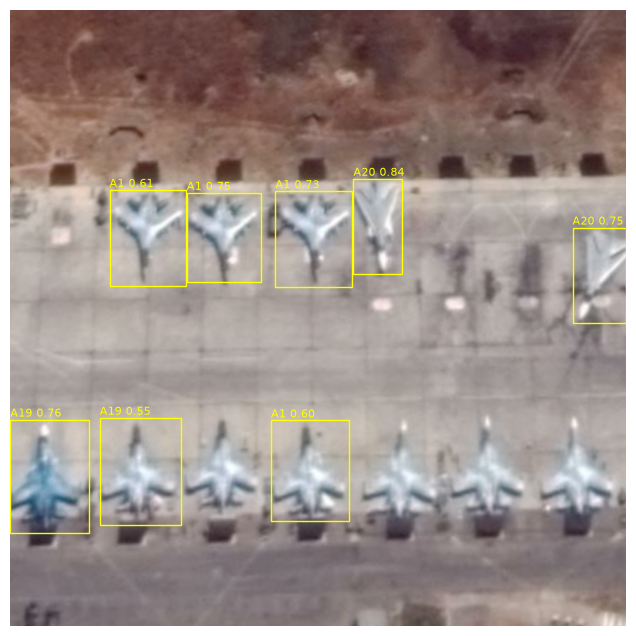

,type,confiance détecteur,confiance classifieur,confiance finale
0,A19,0.88,0.86,0.76
1,A1,0.88,0.69,0.61
2,A1,0.87,0.84,0.73
3,A20,0.87,0.96,0.84
4,A1,0.87,0.86,0.75
5,A1,0.86,0.70,0.60
6,A19,0.85,0.65,0.55
7,A20,0.83,0.90,0.75


In [4]:
objects = load_annotations()
split = pd.read_csv(SPLITS_FILE, dtype={"image_id": str}).set_index("image_id")["split"]

IMAGE_ID = "1453"
image = cv2.imread(str(RAW_IMAGES_DIR / f"{IMAGE_ID}.jpg"))
start = time.perf_counter()
detections = pipeline.predict(image)
print(
    f"Image {IMAGE_ID} ({split[IMAGE_ID]}) : {len(detections)} avions trouvés"
    f" en {time.perf_counter() - start:.2f} s"
)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
for d in detections:
    xmin, ymin, xmax, ymax = d.box
    ax.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="yellow"))
    ax.text(xmin, ymin - 4, f"{d.class_name} {d.score:.2f}", color="yellow", fontsize=8)
ax.axis("off")
plt.show()

pd.DataFrame(
    [
        {
            "type": d.class_name,
            "confiance détecteur": d.detector_score,
            "confiance classifieur": d.classifier_score,
            "confiance finale": d.score,
        }
        for d in detections
    ]
).round(2)

## 3. Comment on corrige une réponse

Pour savoir si une réponse est juste, on la compare aux vraies boîtes du fichier XML
avec l'**IoU** (*Intersection over Union*) : l'aire commune aux deux boîtes divisée
par l'aire qu'elles couvrent ensemble, de 0 (aucun recouvrement) à 1 (parfait).

Les réponses sont prises de la plus sûre à la moins sûre. Chacune est associée au vrai
avion **encore libre** qu'elle recouvre le mieux, avec une IoU d'au moins 0,5 :

| Verdict | Quand |
|---|---|
| **bon type** (vrai positif) | elle recouvre un vrai avion et donne le bon type |
| **mauvais type** | elle recouvre un vrai avion, mais se trompe de type |
| **fausse alarme** (faux positif) | elle ne recouvre aucun avion libre, par exemple une 2e boîte sur un avion déjà trouvé |
| **oublié** (faux négatif) | un vrai avion qu'aucune réponse n'a trouvé |

Puis, en additionnant les avions de toutes les images :
- **précision** = bons types / réponses données ;
- **rappel** = bons types / vrais avions ;
- **F1** = 2 × précision × rappel / (précision + rappel).

In [5]:
def box_iou(boxes_a: np.ndarray, boxes_b: np.ndarray) -> np.ndarray:
    """IoU de chaque boîte de A avec chaque boîte de B (format xmin, ymin, xmax, ymax)."""
    a, b = boxes_a[:, None, :], boxes_b[None, :, :]
    inter_w = np.clip(np.minimum(a[..., 2], b[..., 2]) - np.maximum(a[..., 0], b[..., 0]), 0, None)
    inter_h = np.clip(np.minimum(a[..., 3], b[..., 3]) - np.maximum(a[..., 1], b[..., 1]), 0, None)
    intersection = inter_w * inter_h
    area_a = (a[..., 2] - a[..., 0]) * (a[..., 3] - a[..., 1])
    area_b = (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return intersection / (area_a + area_b - intersection + 1e-9)


def match_details(true_boxes, true_classes, pred_boxes, pred_classes, pred_scores):
    """Le verdict de CHAQUE prédiction face à la vérité (aussi utilisé par l'interface, app.py).

    Les prédictions sont prises de la plus sûre à la moins sûre ; chacune est associée à l'avion
    encore libre qu'elle recouvre le mieux (IoU >= 0,5) :
    - "bon_type" / "mauvais_type" selon la classe prédite ;
    - "fausse_alarme" (faux positif) si elle ne recouvre aucun avion libre.
    Un avion qu'aucune prédiction ne recouvre est MANQUÉ (faux négatif).
    Un mauvais type compte à la fois comme faux positif et comme faux négatif.

    Renvoie : le statut de chaque prédiction, l'indice de l'avion réel associé (ou None), et la
    liste des indices des avions manqués.
    """
    true_boxes = np.asarray(true_boxes, float).reshape(-1, 4)
    pred_boxes = np.asarray(pred_boxes, float).reshape(-1, 4)
    true_classes, pred_classes = np.asarray(true_classes), np.asarray(pred_classes)
    pred_scores = np.asarray(pred_scores, float)
    iou = box_iou(pred_boxes, true_boxes) if len(true_boxes) else np.zeros((len(pred_boxes), 0))
    statuses, matched = ["fausse_alarme"] * len(pred_boxes), [None] * len(pred_boxes)
    taken = set()
    for p in np.argsort(-pred_scores):
        free = [t for t in np.argsort(-iou[p]) if iou[p, t] >= 0.5 and t not in taken]
        if free:  # un vrai avion encore libre, avec une IoU d'au moins 0,5
            taken.add(free[0])
            matched[p] = int(free[0])  # indice du vrai avion associé
            same_type = true_classes[free[0]] == pred_classes[p]
            statuses[p] = "bon_type" if same_type else "mauvais_type"
    missed = [t for t in range(len(true_boxes)) if t not in taken]
    return statuses, matched, missed


def compter(truth: pd.DataFrame, detections: list[Detection], min_score: float) -> dict:
    """Décompte d'une image, en ne gardant que les réponses d'au moins min_score."""
    kept = [d for d in detections if d.score >= min_score]
    statuses, _, missed = match_details(
        truth[["xmin", "ymin", "xmax", "ymax"]].to_numpy(),
        truth["class_name"].to_numpy(),
        [d.box for d in kept],
        np.array([d.class_name for d in kept]),
        [d.score for d in kept],
    )
    return {
        "bon type": statuses.count("bon_type"),
        "mauvais type": statuses.count("mauvais_type"),
        "fausses alarmes": statuses.count("fausse_alarme"),
        "oubliés": len(missed),
    }


compter(objects[objects["image_id"] == IMAGE_ID], detections, DEFAULT_MIN_SCORE)

{'bon type': 7, 'mauvais type': 1, 'fausses alarmes': 0, 'oubliés': 4}

## 4. Le choix du seuil, sur la validation

Le seuil règle le compromis entre **précision** et **rappel** :
- un seuil **bas** donne plus de réponses, donc moins d'oubliés, mais plus d'erreurs ;
- un seuil **haut** donne moins d'erreurs, mais plus d'oubliés.

On fait tourner le système **une fois** sur les 130 images de validation, en gardant
toutes les réponses (confiance d'au moins 0,01), puis on compte les résultats pour
plusieurs seuils. Le seuil a été choisi ainsi, **sur la validation, jamais sur le
test**. Compter environ une minute.

In [6]:
pipeline_toutes = AircraftPipeline(min_score=0.01)
val_ids = sorted(split.index[split == "val"])
val_objects = objects[objects["image_id"].isin(val_ids)]
toutes = {
    image_id: pipeline_toutes.predict(cv2.imread(str(RAW_IMAGES_DIR / f"{image_id}.jpg")))
    for image_id in tqdm(val_ids, desc="Validation")
}

lignes = []
for seuil in [0.25, 0.3, 0.4, 0.5, 0.6, 0.7]:
    total = pd.DataFrame(
        [
            compter(truth, toutes[image_id], seuil)
            for image_id, truth in val_objects.groupby("image_id")
        ]
    ).sum()
    reponses = total["bon type"] + total["mauvais type"] + total["fausses alarmes"]
    precision, rappel = total["bon type"] / reponses, total["bon type"] / len(val_objects)
    lignes.append(
        {
            "seuil": seuil,
            **total.to_dict(),
            "précision": precision,
            "rappel": rappel,
            "F1": 2 * precision * rappel / (precision + rappel),
        }
    )
print(f"{len(val_ids)} images, {len(val_objects)} avions en validation")
pd.DataFrame(lignes).set_index("seuil").round(3)

Validation: 100%|██████████| 130/130 [00:42<00:00,  3.06it/s]


130 images, 787 avions en validation


,bon type,mauvais type,fausses alarmes,oubliés,précision,rappel,F1
seuil,,,,,,,
0.25,784,3,16,0,0.976,0.996,0.986
0.30,782,3,9,2,0.985,0.994,0.989
0.40,779,2,5,6,0.991,0.990,0.990
0.50,767,1,4,19,0.994,0.975,0.984
0.60,748,0,3,39,0.996,0.950,0.973
0.70,650,0,2,137,0.997,0.826,0.903


Le seuil de 0,5 a été choisi parce qu'il faisait le moins d'erreurs (1 mauvais type et
4 fausses alarmes pour 787 avions), avec une F1 parmi les meilleures. Puis il a été
**figé**, avant de toucher au test.

À noter : recalculé avec le détecteur final, le seuil de 0,4 donne une F1 un peu
meilleure (0,990 contre 0,984). On l'a vu après avoir mesuré le test. Changer le seuil
à ce moment-là, ce serait régler le modèle grâce au test : il reste donc à 0,5, et 0,4
est noté comme amélioration possible (journal des décisions, D14 et D16).

## 5. Le résultat final, sur le test

Le test (131 images, 788 avions) a été mesuré **une seule fois**, à la toute fin,
avec ce même code et les réglages figés. On relit le résultat enregistré, sans le
recalculer : le test ne doit servir à régler quoi que ce soit.

Le **témoin** est un YOLO à 20 classes, qui détecte et classe en un seul passage. Il a
été mesuré exactement de la même façon, pour comparer notre architecture à la
solution la plus simple.

In [7]:
test = json.loads((RUNS_DIR / "comparaison_test" / "metrics.json").read_text(encoding="utf-8"))
pd.DataFrame(
    {
        nom: {
            "bon type": r["au_seuil"]["bon_type"],
            "mauvais type": r["au_seuil"]["mauvais_type"],
            "fausses alarmes": r["au_seuil"]["fausses_alarmes"],
            "oubliés": r["au_seuil"]["manques"],
            "précision": r["au_seuil"]["precision"],
            "rappel": r["au_seuil"]["rappel"],
            "F1 (seuil 0,5)": r["au_seuil"]["f1"],
            "mAP50 (tous les seuils)": r["mAP50"],
            "temps par image (ms)": r["ms_par_image_cpu"],
        }
        for nom, r in [
            ("deux étages (nous)", test["deux_etages"]),
            ("témoin YOLO 20 classes", test["temoin_yolo20"]),
        ]
    }
).round(3)

,deux étages (nous),témoin YOLO 20 classes
bon type,729.000,717.000
mauvais type,9.000,49.000
fausses alarmes,3.000,19.000
oubliés,50.000,22.000
précision,0.984,0.913
rappel,0.925,0.910
"F1 (seuil 0,5)",0.954,0.912
mAP50 (tous les seuils),0.957,0.940
temps par image (ms),202.109,72.389


Notre système fait **5 fois moins de mauvais types** que le témoin (9 contre 49) et
**6 fois moins de fausses alarmes** (3 contre 19). Il est plus lent (deux modèles au
lieu d'un), mais reste à environ 0,2 seconde par image.

## 6. Le corpus de test annoté

Le rendu demande un lien vers le **corpus de test annoté par le modèle** : les
131 images de test, avec les avions trouvés par notre système, dans le même format
que le dataset du prof (un fichier XML Pascal VOC par image). Il est dans
`reports/corpus_test_annote/`, avec une image d'aperçu par image et un tableau
`detections.csv`. Ici, le modèle annote ; il n'est pas noté.

Deux niveaux de confiance :
- **avion sûr** : confiance finale d'au moins 0,5, le seuil de l'application ;
- **avion à vérifier** : le détecteur est sûr de voir un avion (au moins 0,6), mais la
  confiance finale est plus basse, le plus souvent parce que le type est incertain.
  C'est à un humain de trancher. Dans le XML, la balise `<a_verifier>` vaut 1.

Le corpus est déjà écrit : mettre `ANNOTER_CORPUS = True` le réécrit (environ une
minute ; la notice `LISEZMOI.md` et les images d'origine ne sont pas touchées).

In [8]:
def class_color(class_name: str) -> tuple[int, int, int]:
    """Couleur RGB (0-255) fixe pour chaque classe, tirée de la palette « tab20 » (20 couleurs)."""
    r, g, b, _ = plt.get_cmap("tab20")(CLASS_TO_INDEX[class_name])
    return int(r * 255), int(g * 255), int(b * 255)


def draw_boxes(image, boxes, labels, thickness=2):
    """Dessine des boîtes (xmin, ymin, xmax, ymax) et leur étiquette sur une COPIE de l'image RGB.

    Chaque étiquette doit commencer par un nom de classe (ex. "A10 0.93") : il sert à choisir
    la couleur de la boîte.
    """
    image = image.copy()  # on ne modifie pas l'image d'origine
    colors = [class_color(label.split()[0]) for label in labels]
    for (xmin, ymin, xmax, ymax), label, color in zip(boxes, labels, colors, strict=True):
        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), color, thickness)
        cv2.putText(
            image, label, (xmin, max(ymin - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2
        )
    return image


BORDER = 2  # pixels : une boîte qui touche le bord de l'image est marquée « tronquée »


def draw_detections(image: np.ndarray, detections) -> np.ndarray:
    """Boîtes épaisses pour les avions sûrs, fines et marquées « ? » pour les à vérifier."""
    for to_review, thickness, mark in ((False, 3, ""), (True, 1, " ?")):
        group = [d for d in detections if d.to_review == to_review]
        image = draw_boxes(
            image,
            [tuple(round(v) for v in d.box) for d in group],
            [f"{d.class_name}{mark} {d.score:.2f}" for d in group],
            thickness=thickness,
        )
    return image


def _add(parent: ET.Element, tag: str, text) -> ET.Element:
    element = ET.SubElement(parent, tag)
    element.text = str(text)
    return element


def detections_to_voc(image_name: str, width: int, height: int, detections) -> ET.ElementTree:
    """Le fichier XML d'une image, au format Pascal VOC (comme les annotations du prof)."""
    root = ET.Element("annotation")
    _add(root, "folder", "corpus_test_annote")
    _add(root, "filename", image_name)
    source = ET.SubElement(root, "source")
    _add(
        source, "annotation", "prédictions du modèle : détecteur YOLO11n puis classifieur ResNet-18"
    )
    size = ET.SubElement(root, "size")
    _add(size, "width", width)
    _add(size, "height", height)
    _add(size, "depth", 3)
    _add(root, "segmented", 0)

    for d in detections:
        xmin, ymin, xmax, ymax = (round(v) for v in d.box)
        touches_border = (
            xmin <= BORDER or ymin <= BORDER or xmax >= width - BORDER or ymax >= height - BORDER
        )
        obj = ET.SubElement(root, "object")
        _add(obj, "name", d.class_name)
        _add(obj, "pose", "Unspecified")
        _add(obj, "truncated", int(touches_border))
        _add(obj, "difficult", 0)
        box = ET.SubElement(obj, "bndbox")
        for tag, value in zip(
            ("xmin", "ymin", "xmax", "ymax"), (xmin, ymin, xmax, ymax), strict=True
        ):
            _add(box, tag, value)
        _add(obj, "score", f"{d.score:.4f}")
        _add(obj, "a_verifier", int(d.to_review))

    tree = ET.ElementTree(root)
    ET.indent(tree, space="\t")  # même mise en forme que les fichiers du dataset
    return tree


def annoter_corpus(out_dir: Path, image_ids: list[str]) -> pd.DataFrame:
    """Écrit un XML et un aperçu par image, et renvoie le tableau de toutes les détections."""
    (out_dir / "annotations").mkdir(parents=True, exist_ok=True)
    (out_dir / "apercus").mkdir(parents=True, exist_ok=True)
    pipeline_corpus = AircraftPipeline(review_min_detector=REVIEW_MIN_DETECTOR)
    rows = []
    for image_id in tqdm(image_ids, desc="Annotation"):
        image = cv2.imread(str(RAW_IMAGES_DIR / f"{image_id}.jpg"))
        height, width = image.shape[:2]
        # Les avions sûrs d'abord, du plus sûr au moins sûr, puis les avions à vérifier
        detections = sorted(pipeline_corpus.predict(image), key=lambda d: (d.to_review, -d.score))
        detections_to_voc(f"{image_id}.jpg", width, height, detections).write(
            out_dir / "annotations" / f"{image_id}.xml", encoding="utf-8", xml_declaration=False
        )
        preview = draw_detections(cv2.cvtColor(image, cv2.COLOR_BGR2RGB), detections)
        cv2.imwrite(
            str(out_dir / "apercus" / f"{image_id}.jpg"), cv2.cvtColor(preview, cv2.COLOR_RGB2BGR)
        )
        for d in detections:
            xmin, ymin, xmax, ymax = (round(v) for v in d.box)
            rows.append(
                {
                    "image": f"{image_id}.jpg",
                    "type": d.class_name,
                    "confiance": round(d.score, 4),
                    "confiance_detecteur": round(d.detector_score, 4),
                    "confiance_classifieur": round(d.classifier_score, 4),
                    "xmin": xmin,
                    "ymin": ymin,
                    "xmax": xmax,
                    "ymax": ymax,
                    "statut": "à vérifier" if d.to_review else "sûr",
                }
            )
    table = pd.DataFrame(rows)
    table.to_csv(out_dir / "detections.csv", index=False)
    return table


CORPUS_DIR = RACINE / "reports" / "corpus_test_annote"
ANNOTER_CORPUS = False  # True : réécrit les XML, les aperçus et detections.csv
test_ids = sorted(split.index[split == "test"])

if ANNOTER_CORPUS:
    corpus = annoter_corpus(CORPUS_DIR, test_ids)
else:
    corpus = pd.read_csv(CORPUS_DIR / "detections.csv")
print(f"{len(test_ids)} images de test annotées :")
print(corpus["statut"].value_counts().to_string())

131 images de test annotées :
statut
sûr           741
à vérifier     61


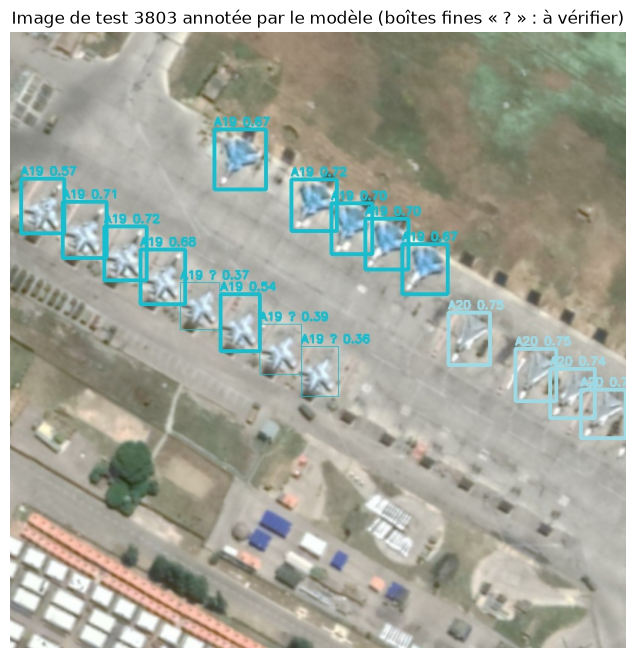

In [9]:
apercu = RACINE / "reports" / "corpus_test_annote" / "apercus" / "3803.jpg"
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(plt.imread(apercu))
ax.set_title("Image de test 3803 annotée par le modèle (boîtes fines « ? » : à vérifier)")
ax.axis("off")
plt.show()

## 7. L'interface graphique

Le prof demande « idéalement » une interface graphique. Voici une version courte, avec
**Gradio** : on choisit une image de test et un seuil, et l'interface dessine les
avions trouvés. Mettre `LANCER_INTERFACE = True`, puis ouvrir le lien affiché.

L'interface complète de la démo, avec la correction en oui / non et le F1 en direct,
se lance avec `oral/lancer_demo.bat`.

In [10]:
import gradio as gr

LANCER_INTERFACE = False


def analyser(image_id: str, seuil: float):
    image = cv2.imread(str(RAW_IMAGES_DIR / f"{image_id}.jpg"))
    pipeline.min_score = seuil
    detections = pipeline.predict(image)
    dessin = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    for d in detections:
        xmin, ymin, xmax, ymax = (round(v) for v in d.box)
        cv2.rectangle(dessin, (xmin, ymin), (xmax, ymax), (255, 220, 0), 2)
        cv2.putText(
            dessin,
            f"{d.class_name} {d.score:.2f}",
            (xmin, max(ymin - 5, 12)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 220, 0),
            2,
        )
    tableau = pd.DataFrame(
        [{"type": d.class_name, "confiance": round(d.score, 2)} for d in detections]
    )
    return dessin, tableau


if LANCER_INTERFACE:
    gr.Interface(
        fn=analyser,
        inputs=[
            gr.Dropdown(test_ids, value="3803", label="Image de test"),
            gr.Slider(0.1, 0.9, value=0.5, step=0.05, label="Seuil de confiance"),
        ],
        outputs=[gr.Image(label="Avions trouvés"), gr.Dataframe(label="Détail")],
        title="Détection et classification d'avions",
    ).launch()

C:\Users\deror\Desktop\projet_ia\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 8. Ce qu'il faut retenir

- **Deux étages** : le détecteur trouve les avions, le classifieur donne leur type,
  et la confiance finale est le produit des deux.
- **Le corpus de test annoté** : un XML par image, avec les avions sûrs et ceux à
  faire vérifier par un humain.
- **Une réponse est juste** si sa boîte recouvre un vrai avion libre avec une IoU d'au
  moins 0,5, et si elle donne le bon type.
- **Le seuil (0,5)** a été choisi sur la validation, puis figé.
- **Le test, une seule fois** : F1 de 0,954, contre 0,912 pour le témoin YOLO à
  20 classes.

**Étape 6, le déploiement** (Docker) : pas encore fait.